# 02 · Busca: recall@1, recall@3 e limiar

A busca usa `intfloat/multilingual-e5-base` (prefixos `query:`/`passage:`, vetores normalizados,
similaridade de cosseno) sobre todos os trechos. O índice fica em cache em `base/indice/` e é refeito
automaticamente se qualquer trecho mudar (hash do conteúdo).

- **recall@k**: fração das perguntas `responde` com ao menos um trecho relevante entre os k primeiros.
- **MRR**: média de 1/posição do primeiro trecho relevante.

> Pré-requisitos: ambiente instalado (`pip install -e .` na raiz) e dados em `base/`, `avaliacao/` e `treino/`. Rode as células em ordem. `REEXECUTAR = False` reaproveita os resultados já gravados para a reexecução ser rápida.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from alerta_ia import config, dados

pd.set_option("display.max_colwidth", 160)
REEXECUTAR = False  # True = refaz as etapas pesadas (GPU) em vez de ler os resultados gravados


def rodar(*args):
    """Executa um módulo do projeto (python -m ...) na raiz do repositório e mostra a saída."""
    r = subprocess.run([sys.executable, "-m", *args], cwd=config.RAIZ, capture_output=True, text=True,
                       encoding="utf-8", errors="replace")
    print(r.stdout[-4000:])
    if r.returncode != 0:
        print(r.stderr[-4000:])
        raise RuntimeError(f"falha ao executar {args}")


def ler_json(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))

In [2]:
from alerta_ia import busca

buscador = busca.Buscador()
print(f"{len(buscador.ids)} trechos indexados, dimensão {buscador.matriz.shape[1]}")

101 trechos indexados, dimensão 768


## Recall no conjunto de teste

In [3]:
res = busca.avaliar_busca(buscador, dados.carregar_casos(config.TESTE))
display(pd.DataFrame([{k: res[k] for k in ["n", "recall@1", "recall@3", "mrr"]}]).round(3))
pd.DataFrame(res["por_categoria"]).T.round(3)

,n,recall@1,recall@3,mrr
0,42,0.833,0.929,0.89


,n,recall@1,recall@3
agua,1.0,0.00,0.0
agua_detalhe_numerico,1.0,1.00,1.0
alertas_canais,4.0,0.75,1.0
alimentos_parafrase,1.0,1.00,1.0
animais,1.0,1.00,1.0
animais_peconhentos,1.0,1.00,1.0
conceitos,1.0,1.00,1.0
criancas,1.0,0.00,0.0
deslizamento_prevencao,3.0,1.00,1.0
deslizamento_sinais,1.0,0.00,1.0


Perguntas em que o trecho relevante **não** apareceu no top-3 (candidatas a erro de busca):

In [4]:
det = pd.DataFrame(res["detalhes"])
det[(det["posicao_primeiro_relevante"].isna()) | (det["posicao_primeiro_relevante"] > 3)]

,id,categoria,top3,relevantes,posicao_primeiro_relevante,similaridade_top1
10,T011,criancas,"[MCID-01-005, MS-03-019, SMSSP-01-002]",[COMDEC-01-005],5,0.838362
34,T035,idosos_pcd,"[COMDEC-01-003, COMDEC-01-002, MCID-01-005]",[MS-03-004],28,0.877774
41,T042,agua,"[MS-03-010, MS-03-020, SMSSP-01-003]",[SEMIL-01-009],8,0.834956


## Calibração do limiar (dev + treino, nunca o teste)

Se a similaridade do top-1 ficar abaixo do limiar, o sistema recusa sem chamar a LLM. A troca é explícita:

- limiar **baixo** → mais perguntas sem resposta chegam à LLM (risco de alucinação);
- limiar **alto** → mais perguntas com resposta são recusadas (recusa indevida).

**Primeira tentativa (v1):** índice de Youden só nas 30 perguntas de dev → limiar 0,8475. No teste ele
barrou 7 das 42 perguntas que tinham resposta: amostra pequena demais (`avaliacao/limiar_v1_dev30.json`).

**Versão final:** calibração em 530 perguntas rotuladas (dev + perguntas de treino) com o critério
`recusa_max`: o maior limiar que barra no máximo 2% das perguntas com resposta. Recusar uma dúvida real de
segurança custa mais do que deixar passar uma pergunta sem resposta, porque a LLM ainda pode recusá-la.
O comando é `python -m alerta_ia.busca calibrar`; aqui lemos o resultado gravado.

In [5]:
pacote = json.loads(config.LIMIAR_JSON.read_text(encoding="utf-8"))
v1 = json.loads((config.DIR_AVALIACAO / "limiar_v1_dev30.json").read_text(encoding="utf-8"))
display(Markdown(f"**Limiar escolhido: {pacote['limiar']:.4f}** (conjunto: {pacote['arquivo']})\n\n{pacote['justificativa']}"))
pd.DataFrame([
    {"versão": "v1 (Youden, 30 de dev)", "limiar": v1["limiar"], **{k: v1["no_limiar"][k] for k in ["sensibilidade", "especificidade", "youden"]}},
    {"versão": "final (recusa_max, 530)", "limiar": pacote["limiar"], **{k: pacote["no_limiar"][k] for k in ["sensibilidade", "especificidade", "youden"]}},
]).round(3)

**Limiar escolhido: 0.8150** (conjunto: dev.jsonl + perguntas_treino.jsonl)

Limiar 0.8150 escolhido no conjunto de calibração (380 perguntas com resposta, 150 sem resposta) como o maior limiar que barra no máximo 2.0% das perguntas com resposta (índice de Youden nesse ponto = 0.362). Nesse ponto, 98.2% das perguntas com resposta seguem para a LLM (recusa indevida causada pelo limiar: 1.8%) e 38.0% das perguntas sem resposta são recusadas antes da LLM (as outras 62.0% dependem da recusa do próprio modelo). Troca: com limiar 0.7950 (mais baixo) passariam 81.3% das sem resposta (mais risco de alucinação) e a recusa indevida seria 0.0%; com 0.8350 (mais alto) a recusa indevida subiria para 6.6% e passariam 39.3% das sem resposta.

,versão,limiar,sensibilidade,especificidade,youden
0,"v1 (Youden, 30 de dev)",0.848,0.950,1.00,0.950
1,"final (recusa_max, 530)",0.815,0.982,0.38,0.362


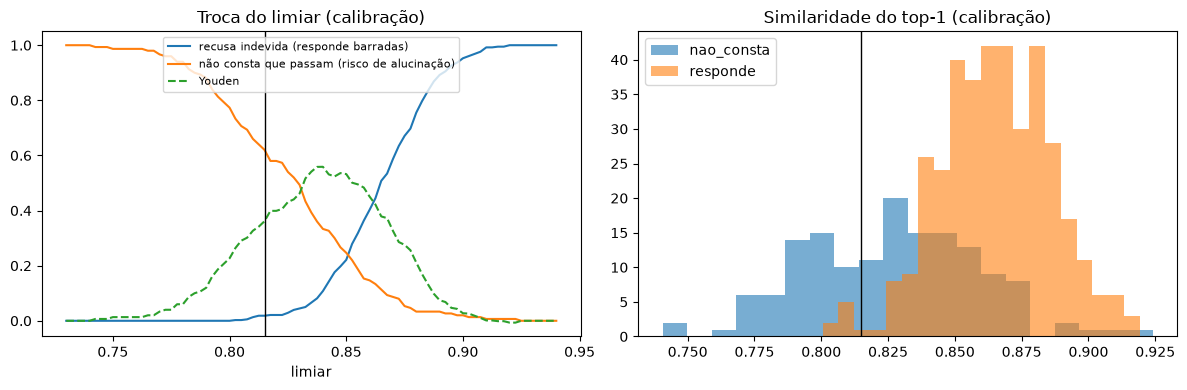

In [6]:
v = pd.DataFrame(pacote["varredura"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(v["limiar"], v["recusa_indevida_pelo_limiar"], label="recusa indevida (responde barradas)")
a1.plot(v["limiar"], v["nao_consta_que_passam"], label="não consta que passam (risco de alucinação)")
a1.plot(v["limiar"], v["youden"], "--", label="Youden")
a1.axvline(pacote["limiar"], color="k", lw=1)
a1.set_xlabel("limiar"); a1.legend(fontsize=8); a1.set_title("Troca do limiar (calibração)")
s = pd.DataFrame(pacote["scores_top1"])
for tipo, g in s.groupby("tipo"):
    a2.hist(g["similaridade_top1"], bins=20, alpha=0.6, label=tipo)
a2.axvline(pacote["limiar"], color="k", lw=1); a2.legend(); a2.set_title("Similaridade do top-1 (calibração)")
plt.tight_layout()

In [7]:
cols = ["limiar", "sensibilidade", "especificidade", "f1", "youden", "recusa_indevida_pelo_limiar",
        "nao_consta_que_passam"]
perto = v.iloc[(v["limiar"] - pacote["limiar"]).abs().argsort()[:9]].sort_values("limiar")
perto[cols].round(3)

,limiar,sensibilidade,especificidade,f1,youden,recusa_indevida_pelo_limiar,nao_consta_que_passam
30,0.805,0.997,0.293,0.876,0.291,0.003,0.707
31,0.808,0.995,0.307,0.877,0.301,0.005,0.693
32,0.810,0.987,0.340,0.878,0.327,0.013,0.660
33,0.812,0.982,0.360,0.879,0.342,0.018,0.640
34,0.815,0.982,0.380,0.882,0.362,0.018,0.620
35,0.818,0.979,0.420,0.887,0.399,0.021,0.580
36,0.820,0.979,0.420,0.887,0.399,0.021,0.580
37,0.822,0.979,0.427,0.888,0.406,0.021,0.573
38,0.825,0.971,0.460,0.889,0.431,0.029,0.540
